**SVM Practice**

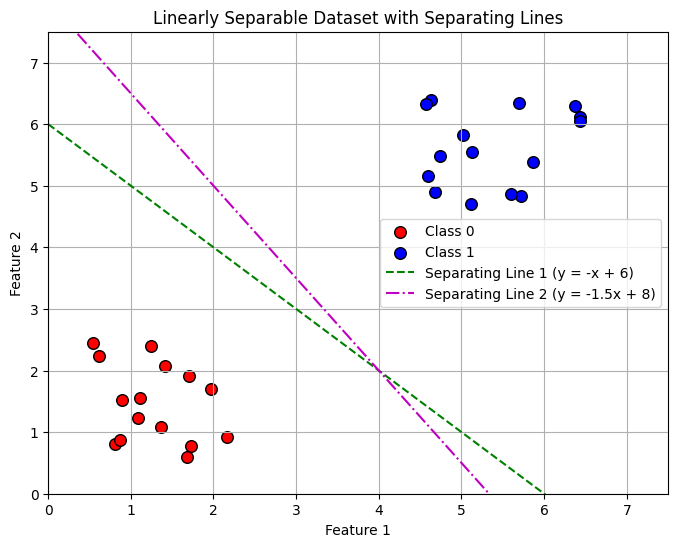

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate a linearly separable 2D dataset
np.random.seed(42)
class_0 = np.random.rand(15, 2) * 2 + 0.5   # points centered roughly around (1.5, 1.5)
class_1 = np.random.rand(15, 2) * 2 + 4.5   # points centered roughly around (5.5, 5.5)

# 2. Define a few lines that separate the two classes
# Equation of a line: y = m*x + c
# Line 1: y = -x + 6
# Line 2: y = -1.5*x + 8
x_vals = np.linspace(0, 7, 100)
y_line1 = -x_vals + 6
y_line2 = -1.5 * x_vals + 8

# 3. Plot the dataset and the separating lines
plt.figure(figsize=(8, 6))
plt.scatter(class_0[:, 0], class_0[:, 1], color='red', label='Class 0', edgecolors='k', s=70)
plt.scatter(class_1[:, 0], class_1[:, 1], color='blue', label='Class 1', edgecolors='k', s=70)

plt.plot(x_vals, y_line1, '--g', label='Separating Line 1 (y = -x + 6)')
plt.plot(x_vals, y_line2, '-.m', label='Separating Line 2 (y = -1.5x + 8)')

plt.xlim(0, 7.5)
plt.ylim(0, 7.5)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Linearly Separable Dataset with Separating Lines')
plt.legend()
plt.grid(True)
plt.show()

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

# Using the class_0 and class_1 datasets defined in the previous cell
def plot_interactive_svm(m=-1.0, c=6.0, margin_width=0.5):
    x_vals = np.linspace(0, 7.5, 100)
    y_line = m * x_vals + c

    # Norm of the weight vector normal to y = mx + c => mx - y + c = 0
    # w = [m, -1], normal vector norm ||w|| = sqrt(m^2 + 1)
    w_norm = np.sqrt(m**2 + 1)

    # Margin lines shifted parallelly by margin_width
    # Distance from line Ax + By + C = 0 is |Ax + By + C| / sqrt(A^2 + B^2)
    # Shifting the intercept c by +/- margin_width * sqrt(m^2 + 1)
    shift = margin_width * w_norm
    y_margin_plus = m * x_vals + (c + shift)
    y_margin_minus = m * x_vals + (c - shift)

    plt.figure(figsize=(9, 7))

    # Plot classes
    plt.scatter(class_0[:, 0], class_0[:, 1], color='red', label='Class 0', edgecolors='k', s=70)
    plt.scatter(class_1[:, 0], class_1[:, 1], color='blue', label='Class 1', edgecolors='k', s=70)

    # Plot separating boundary and margins
    plt.plot(x_vals, y_line, '-g', linewidth=2, label=f'Decision Boundary (y = {m:.2f}x + {c:.2f})')
    plt.plot(x_vals, y_margin_plus, '--k', alpha=0.6, label='Margin +')
    plt.plot(x_vals, y_margin_minus, '--k', alpha=0.6, label='Margin -')

    # Fill the margin area
    plt.fill_between(x_vals, y_margin_minus, y_margin_plus, color='gray', alpha=0.15, label='Margin Zone')

    plt.xlim(0, 7.5)
    plt.ylim(0, 7.5)
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')

    # Total margin width is 2 * margin_width
    total_margin = 2 * margin_width
    plt.title(f'Manual Margin Tuning\nMargin Half-Width: {margin_width:.2f} | Total Margin Size: {total_margin:.2f}')
    plt.legend(loc='upper right')
    plt.grid(True)
    plt.show()

# Create interactive sliders
interact(
    plot_interactive_svm,
    m=FloatSlider(value=-1.1, min=-3.0, max=-0.1, step=0.05, description='Slope (m)'),
    c=FloatSlider(value=6.5, min=3.0, max=10.0, step=0.1, description='Intercept (c)'),
    margin_width=FloatSlider(value=0.8, min=0.0, max=2.5, step=0.05, description='Margin (d)')
);

interactive(children=(FloatSlider(value=-1.1, description='Slope (m)', max=-0.1, min=-3.0, step=0.05), FloatSl…

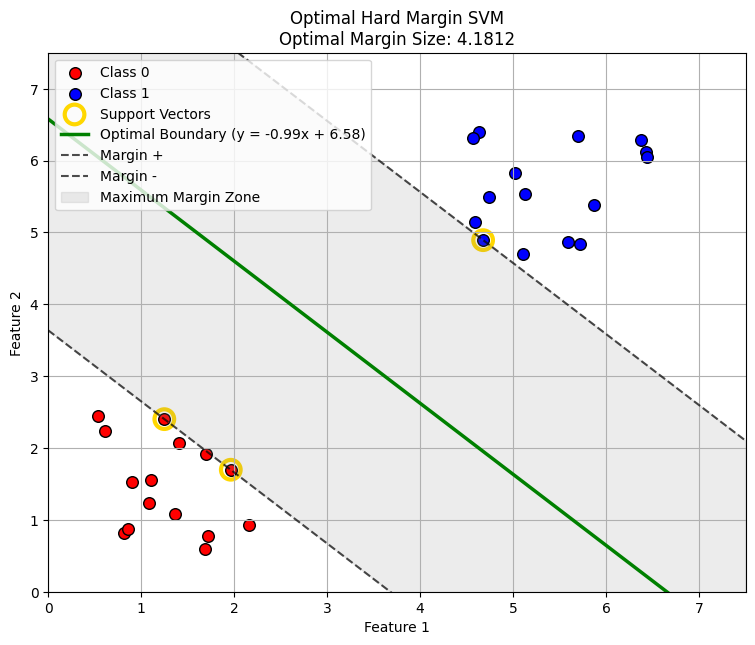

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

# 1. Prepare data for scikit-learn SVM
X = np.vstack((class_0, class_1))
y = np.hstack((np.zeros(len(class_0)), np.ones(len(class_1))))

# 2. Fit a Hard Margin SVM (C is set to a extremely large value to forbid any violations)
clf = SVC(kernel='linear', C=1e10)
clf.fit(X, y)

# Get weight vector and bias
w = clf.coef_[0]
b = clf.intercept_[0]

# The decision boundary equation: w0 * x + w1 * y + b = 0 => y = (-w0/w1) * x - (b/w1)
m_opt = -w[0] / w[1]
c_opt = -b / w[1]

# Calculate margin width d
# The distance between the separating hyperplane and support vectors is 1 / ||w||
margin_width = 1.0 / np.linalg.norm(w)
total_margin_size = 2.0 * margin_width

# 3. Plotting the Optimal Hard Margin SVM
x_vals = np.linspace(0, 7.5, 100)
y_line = m_opt * x_vals + c_opt

# Margins parallel lines
# Shift the intercept c by +/- margin_width * sqrt(m^2 + 1)
w_norm = np.sqrt(m_opt**2 + 1)
shift = margin_width * w_norm
y_margin_plus = m_opt * x_vals + (c_opt + shift)
y_margin_minus = m_opt * x_vals + (c_opt - shift)

plt.figure(figsize=(9, 7))

# Plot datasets
plt.scatter(class_0[:, 0], class_0[:, 1], color='red', label='Class 0', edgecolors='k', s=70)
plt.scatter(class_1[:, 0], class_1[:, 1], color='blue', label='Class 1', edgecolors='k', s=70)

# Highlight Support Vectors
svs = clf.support_vectors_
plt.scatter(svs[:, 0], svs[:, 1], s=200, facecolors='none', edgecolors='gold', linewidths=3, label='Support Vectors')

# Plot decision boundary and margin lines
plt.plot(x_vals, y_line, '-g', linewidth=2.5, label=f'Optimal Boundary (y = {m_opt:.2f}x + {c_opt:.2f})')
plt.plot(x_vals, y_margin_plus, '--k', alpha=0.7, label='Margin +')
plt.plot(x_vals, y_margin_minus, '--k', alpha=0.7, label='Margin -')
plt.fill_between(x_vals, y_margin_minus, y_margin_plus, color='gray', alpha=0.15, label='Maximum Margin Zone')

plt.xlim(0, 7.5)
plt.ylim(0, 7.5)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title(f'Optimal Hard Margin SVM\nOptimal Margin Size: {total_margin_size:.4f}')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

```markdown
## Motivating Soft Margin SVM

When we enforce a strict **Hard Margin** ($C \rightarrow \infty$), we assume the data is perfectly linearly separable and free of noise. Let's see what happens in two problematic cases:
1. **Non-separable data** (overlapping distributions).
2. **Outliers close to the opposing class** (causing a dramatically shrunk margin).
```

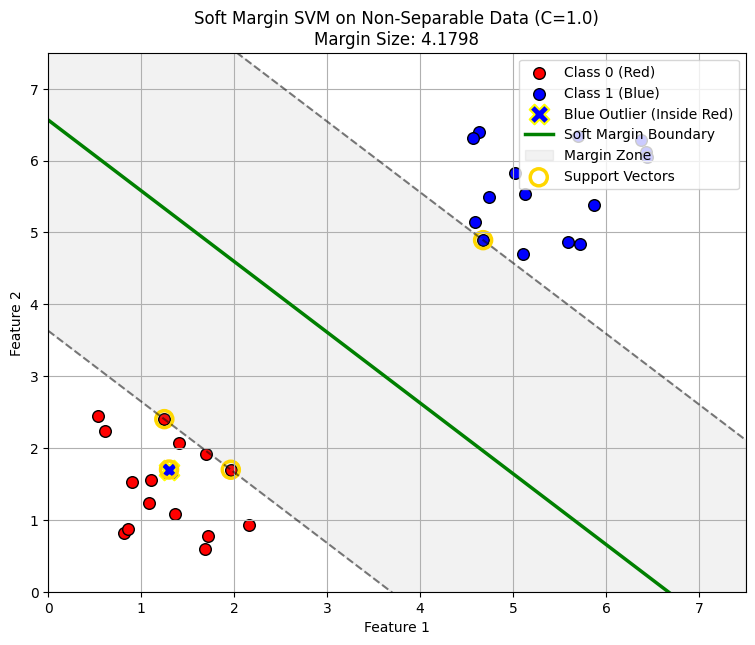

In [28]:
# 1. Add a blue outlier point inside the red cluster (Class 0)
# Class 0 points are located roughly around (1.5, 1.5)
blue_outlier = np.array([[1.3, 1.7]])

# Create a new non-separable dataset
class_1_with_outlier = np.vstack((class_1, blue_outlier))

# Prepare labels and feature matrix
X_non_sep = np.vstack((class_0, class_1_with_outlier))
y_non_sep = np.hstack((np.zeros(len(class_0)), np.ones(len(class_1_with_outlier))))

# 2. Fit a Soft Margin SVM (C=1.0) to find the best general separating line
clf_soft = SVC(kernel='linear', C=1.0)
clf_soft.fit(X_non_sep, y_non_sep)

w_s = clf_soft.coef_[0]
b_s = clf_soft.intercept_[0]
m_s = -w_s[0] / w_s[1]
c_s = -b_s / w_s[1]
margin_s = 1.0 / np.linalg.norm(w_s)

# 3. Plotting the results
x_plot = np.linspace(0, 7.5, 100)
y_plot = m_s * x_plot + c_s

plt.figure(figsize=(9, 7))

# Plot normal classes
plt.scatter(class_0[:, 0], class_0[:, 1], color='red', label='Class 0 (Red)', edgecolors='k', s=70)
# Plot Class 1 without the outlier
plt.scatter(class_1[:, 0], class_1[:, 1], color='blue', label='Class 1 (Blue)', edgecolors='k', s=70)
# Highlight the blue outlier inside the red cluster
plt.scatter(blue_outlier[:, 0], blue_outlier[:, 1], color='blue', marker='X', s=200, edgecolors='yellow', linewidths=1.5, label='Blue Outlier (Inside Red)')

# Plot decision boundary and margin boundaries
w_norm_s = np.sqrt(m_s**2 + 1)
shift_s = margin_s * w_norm_s
y_margin_plus = m_s * x_plot + (c_s + shift_s)
y_margin_minus = m_s * x_plot + (c_s - shift_s)

plt.plot(x_plot, y_plot, '-g', linewidth=2.5, label='Soft Margin Boundary')
plt.plot(x_plot, y_margin_plus, '--k', alpha=0.5)
plt.plot(x_plot, y_margin_minus, '--k', alpha=0.5)
plt.fill_between(x_plot, y_margin_minus, y_margin_plus, color='gray', alpha=0.1, label='Margin Zone')

# Highlight support vectors
plt.scatter(clf_soft.support_vectors_[:, 0], clf_soft.support_vectors_[:, 1], s=150, facecolors='none', edgecolors='gold', linewidths=2.5, label='Support Vectors')

plt.xlim(0, 7.5)
plt.ylim(0, 7.5)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title(f'Soft Margin SVM on Non-Separable Data (C=1.0)\nMargin Size: {2 * margin_s:.4f}')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

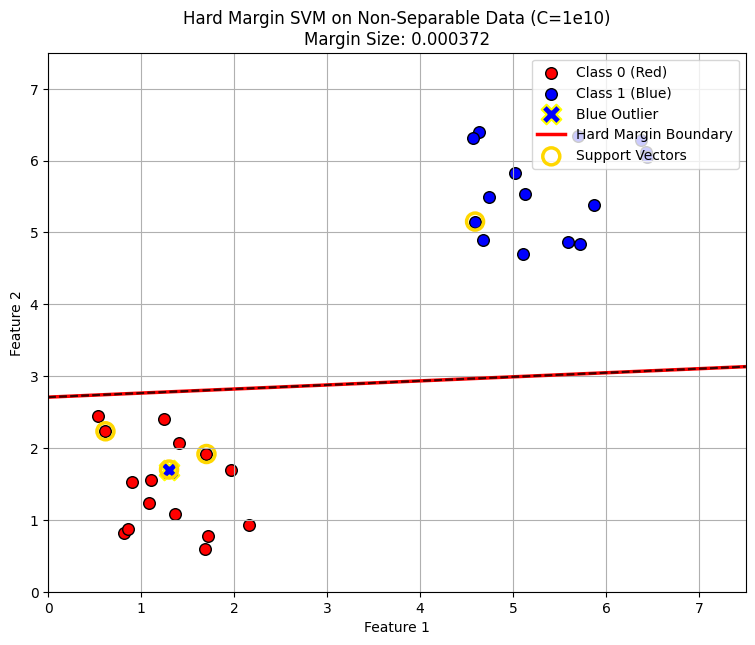

In [29]:
# Try fitting a Hard Margin SVM on the non-separable dataset
# We set C to an extremely large value (1e10) to forbid any margin violations
clf_hard_non_sep = SVC(kernel='linear', C=1e10)

try:
    clf_hard_non_sep.fit(X_non_sep, y_non_sep)

    w_h = clf_hard_non_sep.coef_[0]
    b_h = clf_hard_non_sep.intercept_[0]
    m_h = -w_h[0] / w_h[1]
    c_h = -b_h / w_h[1]
    margin_h = 1.0 / np.linalg.norm(w_h)

    # Plotting
    x_plot = np.linspace(0, 7.5, 100)
    y_plot_hard = m_h * x_plot + c_h
    w_norm_h = np.sqrt(m_h**2 + 1)
    shift_h = margin_h * w_norm_h

    plt.figure(figsize=(9, 7))
    plt.scatter(class_0[:, 0], class_0[:, 1], color='red', label='Class 0 (Red)', edgecolors='k', s=70)
    plt.scatter(class_1[:, 0], class_1[:, 1], color='blue', label='Class 1 (Blue)', edgecolors='k', s=70)
    plt.scatter(blue_outlier[:, 0], blue_outlier[:, 1], color='blue', marker='X', s=200, edgecolors='yellow', linewidths=1.5, label='Blue Outlier')

    plt.plot(x_plot, y_plot_hard, '-r', linewidth=2.5, label='Hard Margin Boundary')
    plt.plot(x_plot, m_h * x_plot + (c_h + shift_h), '--k', alpha=0.5)
    plt.plot(x_plot, m_h * x_plot + (c_h - shift_h), '--k', alpha=0.5)

    plt.scatter(clf_hard_non_sep.support_vectors_[:, 0], clf_hard_non_sep.support_vectors_[:, 1], s=150, facecolors='none', edgecolors='gold', linewidths=2.5, label='Support Vectors')

    plt.xlim(0, 7.5)
    plt.ylim(0, 7.5)
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.title(f'Hard Margin SVM on Non-Separable Data (C=1e10)\nMargin Size: {2 * margin_h:.6f}')
    plt.legend(loc='upper right')
    plt.grid(True)
    plt.show()

except Exception as e:
    print(f"An error occurred during fitting: {e}")

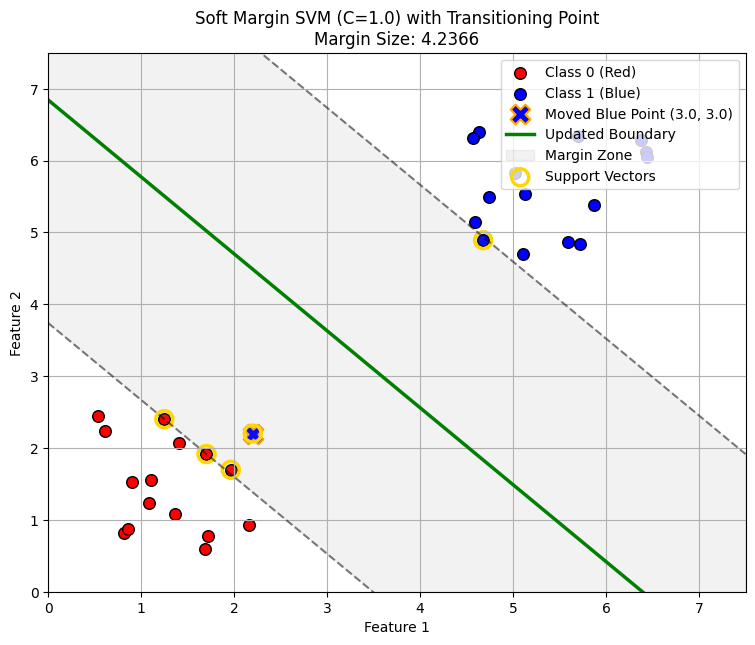

In [36]:
# 1. Relocate the blue outlier closer to the blue cluster, but still near the red cluster
# Let's place it at (3.0, 3.0)
blue_transition_point = np.array([[2.2, 2.2]])

# Create the updated dataset with the transition point
class_1_updated = np.vstack((class_1, blue_transition_point))
X_updated = np.vstack((class_0, class_1_updated))
y_updated = np.hstack((np.zeros(len(class_0)), np.ones(len(class_1_updated))))

# 2. Fit Soft Margin SVM (C=1.0)
clf_updated = SVC(kernel='linear', C=0.1)
clf_updated.fit(X_updated, y_updated)

w_u = clf_updated.coef_[0]
b_u = clf_updated.intercept_[0]
m_u = -w_u[0] / w_u[1]
try:
    c_u = -b_u / w_u[1]
except ZeroDivisionError:
    c_u = 0
margin_u = 1.0 / np.linalg.norm(w_u)

# 3. Plotting
x_plot = np.linspace(0, 7.5, 100)
y_plot_updated = m_u * x_plot + c_u
w_norm_u = np.sqrt(m_u**2 + 1)
shift_u = margin_u * w_norm_u

plt.figure(figsize=(9, 7))
plt.scatter(class_0[:, 0], class_0[:, 1], color='red', label='Class 0 (Red)', edgecolors='k', s=70)
plt.scatter(class_1[:, 0], class_1[:, 1], color='blue', label='Class 1 (Blue)', edgecolors='k', s=70)
plt.scatter(blue_transition_point[:, 0], blue_transition_point[:, 1], color='blue', marker='X', s=200, edgecolors='orange', linewidths=1.5, label='Moved Blue Point (3.0, 3.0)')

# Plot boundaries
plt.plot(x_plot, y_plot_updated, '-g', linewidth=2.5, label='Updated Boundary')
plt.plot(x_plot, y_plot_updated + shift_u, '--k', alpha=0.5)
plt.plot(x_plot, y_plot_updated - shift_u, '--k', alpha=0.5)
plt.fill_between(x_plot, y_plot_updated - shift_u, y_plot_updated + shift_u, color='gray', alpha=0.1, label='Margin Zone')

# Highlight support vectors
plt.scatter(clf_updated.support_vectors_[:, 0], clf_updated.support_vectors_[:, 1], s=150, facecolors='none', edgecolors='gold', linewidths=2.5, label='Support Vectors')

plt.xlim(0, 7.5)
plt.ylim(0, 7.5)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title(f'Soft Margin SVM (C=1.0) with Transitioning Point\nMargin Size: {2 * margin_u:.4f}')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

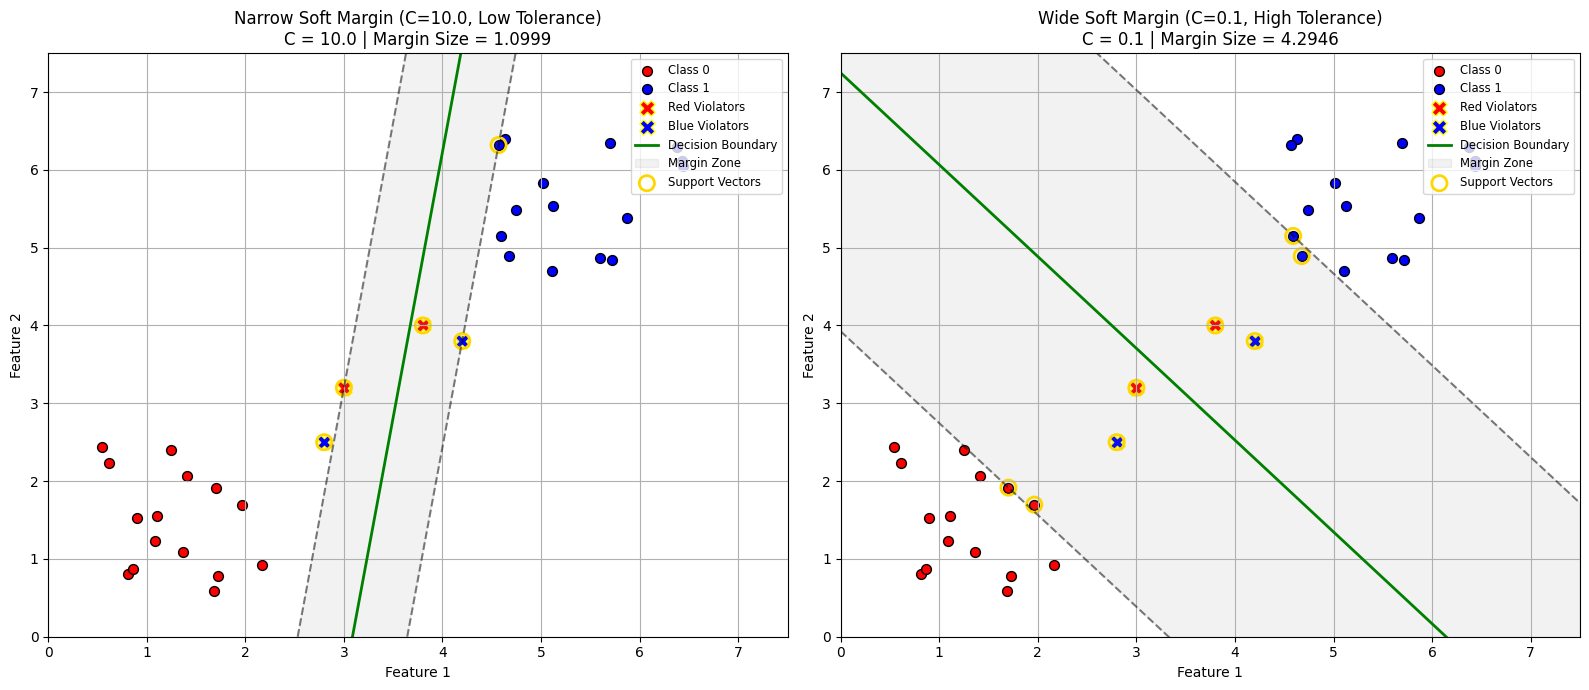

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

# 1. Regenerate class_0 and class_1
np.random.seed(42)
class_0 = np.random.rand(15, 2) * 2 + 0.5   # centered roughly around (1.5, 1.5)
class_1 = np.random.rand(15, 2) * 2 + 4.5   # centered roughly around (5.5, 5.5)

# 2. Add multiple points that explicitly violate the margins or are misclassified
# We will add some Class 0 points (Red) closer to/inside the Class 1 region
violators_0 = np.array([
    [3.0, 3.2],  # Deep inside the margin zone
    [3.8, 4.0]   # Completely on the other side (misclassified)
])

# We will add some Class 1 points (Blue) closer to/inside the Class 0 region
violators_1 = np.array([
    [4.2, 3.8],  # Inside the margin zone
    [2.8, 2.5]   # Completely on the other side (misclassified)
])

# Combine everything into a highly non-separable dataset
class_0_extended = np.vstack((class_0, violators_0))
class_1_extended = np.vstack((class_1, violators_1))

X_violators = np.vstack((class_0_extended, class_1_extended))
y_violators = np.hstack((np.zeros(len(class_0_extended)), np.ones(len(class_1_extended))))

# 3. Fit two Soft Margin SVMs with different C values
clf_c_high = SVC(kernel='linear', C=10.0)
clf_c_high.fit(X_violators, y_violators)

clf_c_low = SVC(kernel='linear', C=0.1)
clf_c_low.fit(X_violators, y_violators)

# Helper function to plot the decision boundary and margin
def plot_svm_margin(clf, title, ax):
    w = clf.coef_[0]
    b = clf.intercept_[0]
    m = -w[0] / w[1]
    c = -b / w[1]
    margin = 1.0 / np.linalg.norm(w)

    x_plot = np.linspace(0, 7.5, 100)
    y_plot = m * x_plot + c
    w_norm = np.sqrt(m**2 + 1)
    shift = margin * w_norm

    # Scatter base points
    ax.scatter(class_0[:, 0], class_0[:, 1], color='red', label='Class 0', edgecolors='k', s=50)
    ax.scatter(class_1[:, 0], class_1[:, 1], color='blue', label='Class 1', edgecolors='k', s=50)

    # Scatter explicit margin violators with a distinct marker
    ax.scatter(violators_0[:, 0], violators_0[:, 1], color='red', marker='X', s=120, edgecolors='yellow', linewidths=1, label='Red Violators')
    ax.scatter(violators_1[:, 0], violators_1[:, 1], color='blue', marker='X', s=120, edgecolors='yellow', linewidths=1, label='Blue Violators')

    # Plot boundary and margins
    ax.plot(x_plot, y_plot, '-g', linewidth=2, label='Decision Boundary')
    ax.plot(x_plot, y_plot + shift, '--k', alpha=0.5)
    ax.plot(x_plot, y_plot - shift, '--k', alpha=0.5)
    ax.fill_between(x_plot, y_plot - shift, y_plot + shift, color='gray', alpha=0.1, label='Margin Zone')

    # Highlight support vectors
    ax.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=120, facecolors='none', edgecolors='gold', linewidths=2, label='Support Vectors')

    ax.set_xlim(0, 7.5)
    ax.set_ylim(0, 7.5)
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.set_title(f'{title}\nC = {clf.C} | Margin Size = {2 * margin:.4f}')
    ax.legend(loc='upper right', fontsize='small')
    ax.grid(True)

# 4. Compare the plots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
plot_svm_margin(clf_c_high, "Narrow Soft Margin (C=10.0, Low Tolerance)", axes[0])
plot_svm_margin(clf_c_low, "Wide Soft Margin (C=0.1, High Tolerance)", axes[1])
plt.tight_layout()
plt.show()

```markdown
## Comparing SVM Implementations in Scikit-Learn

We will compare three different classes in Scikit-Learn that can be used to fit a Linear SVM:
1. `SVC(kernel='linear')` (LibSVM-based)
2. `LinearSVC` (LibLinear-based, optimized for linear formulation)
3. `SGDClassifier(loss='hinge')` (Stochastic Gradient Descent optimizer solving hinge loss)
```

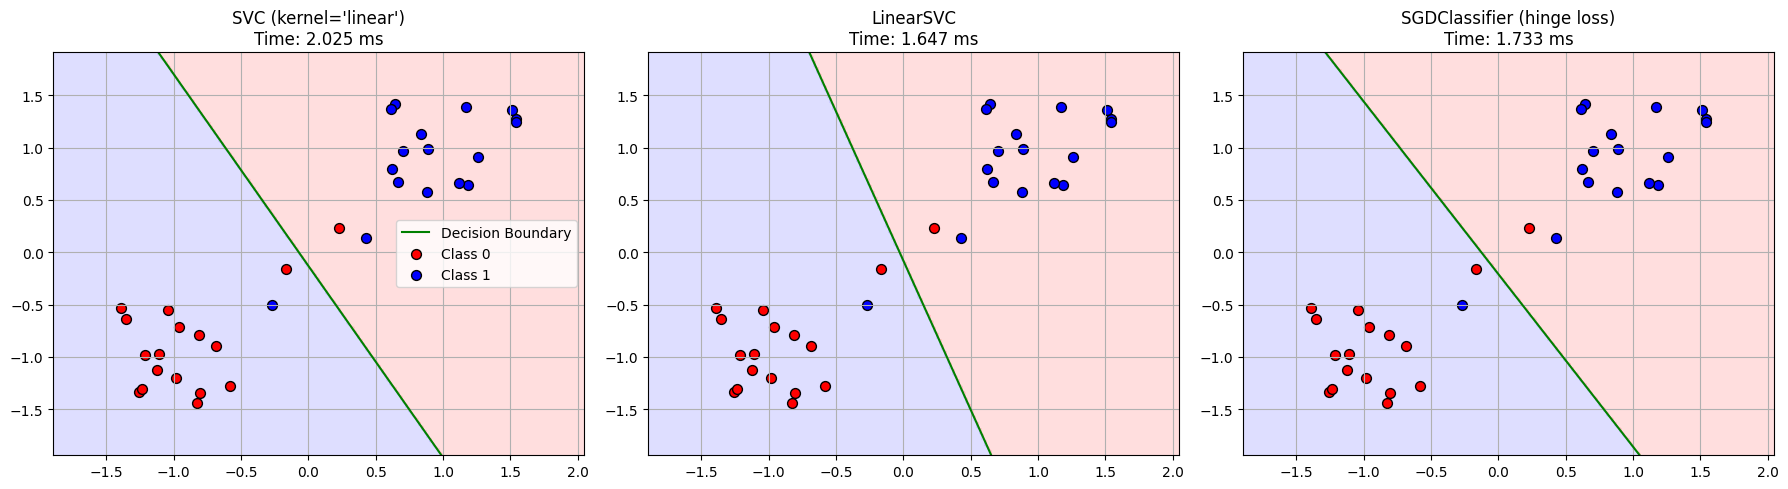

In [38]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Standardizing is highly recommended for SVMs, especially for SGD
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_violators)

# 1. Initialize the three different models
# We align C and alpha parameters: SGD alpha = 1 / (N * C)
C_val = 1.0
alpha_val = 1.0 / (len(X_scaled) * C_val)

models = {
    "SVC (kernel='linear')": SVC(kernel='linear', C=C_val),
    "LinearSVC": LinearSVC(C=C_val, dual=False, random_state=42),
    "SGDClassifier (hinge loss)": SGDClassifier(loss='hinge', alpha=alpha_val, max_iter=10000, random_state=42)
}

# 2. Train each model and record training time
plt.figure(figsize=(18, 5))
x_min, x_max = X_scaled[:, 0].min() - 0.5, X_scaled[:, 0].max() + 0.5
y_min, y_max = X_scaled[:, 1].min() - 0.5, X_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

for i, (name, clf) in enumerate(models.items(), 1):
    start_time = time.perf_counter()
    clf.fit(X_scaled, y_violators)
    elapsed_time = (time.perf_counter() - start_time) * 1000 # in ms

    # Plotting
    ax = plt.subplot(1, 3, i)
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.15, cmap='bwr')

    # Plot boundary line: w0*x + w1*y + b = 0 => y = -w0/w1 * x - b/w1
    w = clf.coef_[0]
    b = clf.intercept_[0]
    x_line = np.linspace(x_min, x_max, 100)
    y_line = -w[0]/w[1] * x_line - b/w[1]
    ax.plot(x_line, y_line, '-g', label='Decision Boundary')

    # Plot data points
    ax.scatter(X_scaled[y_violators==0, 0], X_scaled[y_violators==0, 1], color='red', edgecolors='k', s=50, label='Class 0')
    ax.scatter(X_scaled[y_violators==1, 0], X_scaled[y_violators==1, 1], color='blue', edgecolors='k', s=50, label='Class 1')

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_title(f"{name}\nTime: {elapsed_time:.3f} ms")
    ax.grid(True)
    if i == 1:
        ax.legend()

plt.tight_layout()
plt.show()

### Key Differences and Takeaways

| Feature | `SVC(kernel='linear')` | `LinearSVC` | `SGDClassifier(loss='hinge')` |
| :--- | :--- | :--- | :--- |
| **Underlying Library** | LibSVM | LibLinear | Custom scikit-learn SGD engine |
| **Optimization Problem**| Solves the **dual** formulation | Solves the **primal** formulation | Solves via **Stochastic Gradient Descent** |
| **Complexity (Samples)** | $O(n_{\text{samples}}^2 \cdot n_{\text{features}})$ (Quadratic) | $O(n_{\text{samples}} \cdot n_{\text{features}})$ (Linear) | $O(n_{\text{samples}} \cdot n_{\text{features}})$ (Linear) |
| **Speed on Large Data** | Very slow | Fast | Extremely fast (supports online/incremental learning) |
| **Memory Footprint** | High (stores kernel/Gram matrix) | Low | Extremely low |
| **Kernel Trick** | **Supported** (can switch to RBF, Poly, etc.) | **Not Supported** (Strictly linear) | **Not Supported** (Strictly linear) |

### Summary Recommendation
1. Use **`LinearSVC`** by default when you need a fast, linear SVM decision boundary.
2. Use **`SVC(kernel='linear')`** only on small datasets, or when you eventually intend to test non-linear kernels (`kernel='rbf'`).
3. Use **`SGDClassifier(loss='hinge')`** for massive datasets (millions of rows) or when implementing out-of-core / online streaming pipelines.


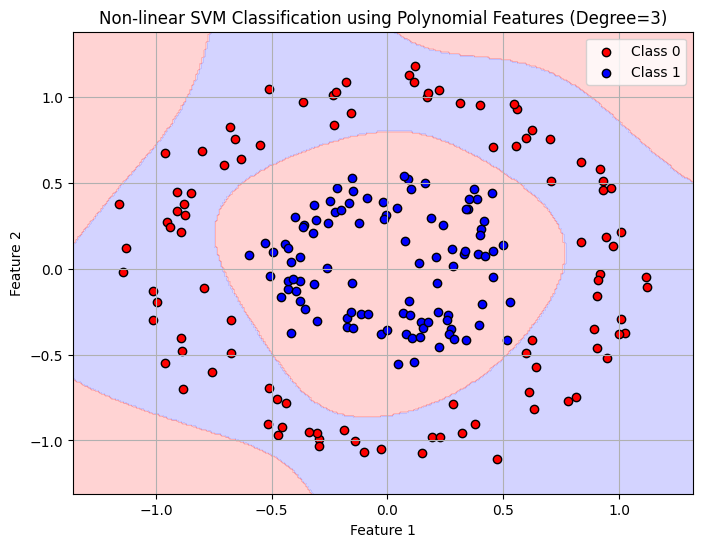

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.pipeline import Pipeline

# 1. Import preprocessors and classifier
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import LinearSVC

# 2. Generate a concentric circle dataset (strictly non-linearly separable in 2D)
X_circles, y_circles = make_circles(n_samples=200, noise=0.1, factor=0.4, random_state=42)

# 3. Build a pipeline adding 3rd-degree polynomial features
poly_svm_clf = Pipeline([
    ("poly_features", PolynomialFeatures(degree=10)),
    ("scaler", StandardScaler()),
    ("svm_clf", LinearSVC(C=10, loss="hinge", max_iter=10000, random_state=42))
])

poly_svm_clf.fit(X_circles, y_circles)

# 4. Create grid to plot decision boundary
x_min, x_max = X_circles[:, 0].min() - 0.2, X_circles[:, 0].max() + 0.2
y_min, y_max = X_circles[:, 1].min() - 0.2, X_circles[:, 1].max() + 0.2
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
Z = poly_svm_clf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 5. Visualize results
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.2, cmap='bwr')

plt.scatter(X_circles[y_circles == 0, 0], X_circles[y_circles == 0, 1], color='red', edgecolors='k', label='Class 0')
plt.scatter(X_circles[y_circles == 1, 0], X_circles[y_circles == 1, 1], color='blue', edgecolors='k', label='Class 1')

plt.title("Non-linear SVM Classification using Polynomial Features (Degree=3)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

## Non-linear SVM using the Kernel Trick (RBF Kernel)

Instead of manually expanding the features using `PolynomialFeatures` (which can become computationally expensive for high-degree combinations), we can leverage the **Kernel Trick** using the Radial Basis Function (RBF) kernel.

The RBF kernel mathematically computes similarity between points in an implicit high-dimensional space without ever actually transforming the coordinates:

$$K(\mathbf{x}, \mathbf{x}') = \exp(-\gamma \|\mathbf{x} - \mathbf{x}'\|^2)$$

Let's build a pipeline using `StandardScaler` and `SVC(kernel='rbf')` to classify the concentric circles dataset.

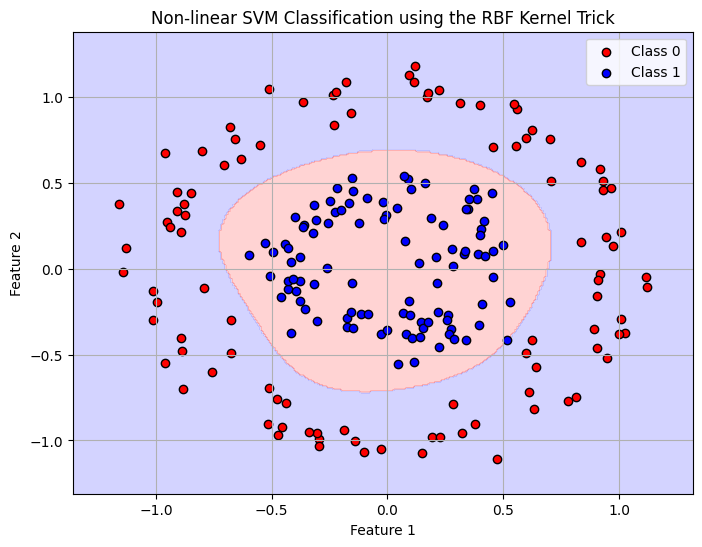

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. Build a pipeline with an RBF Kernel SVM
rbf_kernel_svm_clf = Pipeline([
    ("scaler", StandardScaler()),
    ("svm_clf", SVC(kernel="rbf", gamma=1, C=10, random_state=42))
])

rbf_kernel_svm_clf.fit(X_circles, y_circles)

# 2. Create grid to plot decision boundary
x_min, x_max = X_circles[:, 0].min() - 0.2, X_circles[:, 0].max() + 0.2
y_min, y_max = X_circles[:, 1].min() - 0.2, X_circles[:, 1].max() + 0.2
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
Z = rbf_kernel_svm_clf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 3. Visualize results
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.2, cmap='bwr')

plt.scatter(X_circles[y_circles == 0, 0], X_circles[y_circles == 0, 1], color='red', edgecolors='k', label='Class 0')
plt.scatter(X_circles[y_circles == 1, 0], X_circles[y_circles == 1, 1], color='blue', edgecolors='k', label='Class 1')

plt.title("Non-linear SVM Classification using the RBF Kernel Trick")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

### Visualizing Support Vectors of the RBF SVM

Let's plot the RBF model's decision boundary again, but this time we'll highlight the support vectors (the key points that lie on or violate the margins, which are stored in `rbf_kernel_svm_clf.named_steps['svm_clf'].support_vectors_`).

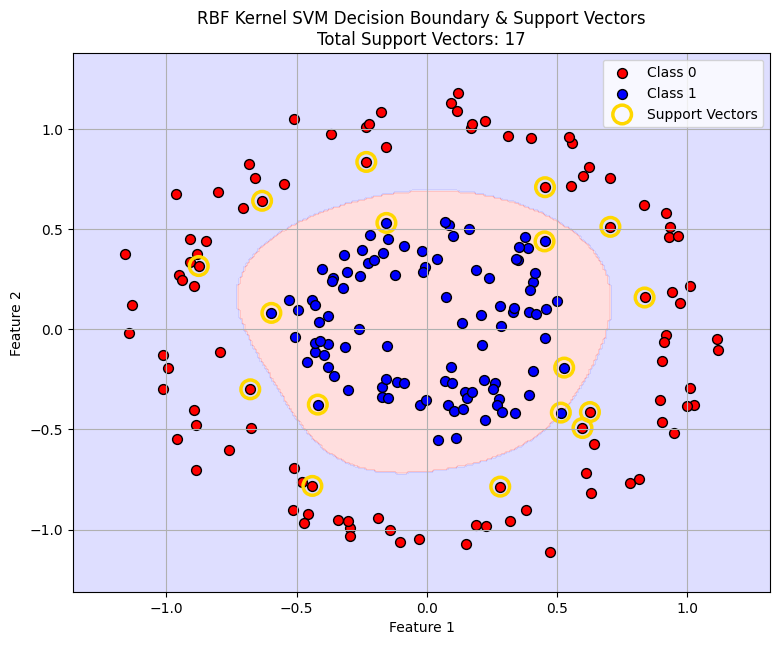

In [45]:
# 1. Retrieve support vectors from the trained RBF SVM within the pipeline
# Note: Support vectors are in the scaled feature space, so we must inverse-transform them back to 2D for visualization.
scaler = rbf_kernel_svm_clf.named_steps['scaler']
svm_clf = rbf_kernel_svm_clf.named_steps['svm_clf']

# Support vectors in scaled space
sv_scaled = svm_clf.support_vectors_
# Transform back to original space
sv_original = scaler.inverse_transform(sv_scaled)

# 2. Plotting
plt.figure(figsize=(9, 7))
plt.contourf(xx, yy, Z, alpha=0.15, cmap='bwr')

# Plot original circles
plt.scatter(X_circles[y_circles == 0, 0], X_circles[y_circles == 0, 1], color='red', edgecolors='k', s=50, label='Class 0')
plt.scatter(X_circles[y_circles == 1, 0], X_circles[y_circles == 1, 1], color='blue', edgecolors='k', s=50, label='Class 1')

# Highlight the Support Vectors in original space
plt.scatter(sv_original[:, 0], sv_original[:, 1], s=180, facecolors='none', edgecolors='gold', linewidths=2.5, label='Support Vectors')

plt.title(f"RBF Kernel SVM Decision Boundary & Support Vectors\nTotal Support Vectors: {len(sv_original)}")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

## Performance Comparison: Polynomial Features vs. RBF Kernel

Let's benchmark both approaches on our concentric circles dataset (`X_circles`, `y_circles`) to compare:
1. **Training & Prediction Time** (using `time.perf_counter`)
2. **Accuracy Score** on the dataset
3. **Decision Boundary Shape**

In [47]:
import time
from sklearn.metrics import accuracy_score

# 1. Benchmark Polynomial Features + LinearSVC
t0 = time.perf_counter()
poly_svm_clf.fit(X_circles, y_circles)
y_pred_poly = poly_svm_clf.predict(X_circles)
t_poly = (time.perf_counter() - t0) * 1000  # in ms
acc_poly = accuracy_score(y_circles, y_pred_poly)

# 2. Benchmark RBF Kernel SVC
t0 = time.perf_counter()
rbf_kernel_svm_clf.fit(X_circles, y_circles)
y_pred_rbf = rbf_kernel_svm_clf.predict(X_circles)
t_rbf = (time.perf_counter() - t0) * 1000  # in ms
acc_rbf = accuracy_score(y_circles, y_pred_rbf)

# 3. Print a summary table
print(f"{'Model / Approach':<40} | {'Accuracy':<10} | {'Time (ms)':<10}")
print("-" * 68)
print(f"{'Polynomial Features (Degree 3) + LinearSVC':<40} | {acc_poly:<10.2%} | {t_poly:<10.3f}")
print(f"{'Implicit RBF Kernel SVC':<40} | {acc_rbf:<10.2%} | {t_rbf:<10.3f}")

Model / Approach                         | Accuracy   | Time (ms) 
--------------------------------------------------------------------
Polynomial Features (Degree 3) + LinearSVC | 100.00%    | 15.599    
Implicit RBF Kernel SVC                  | 100.00%    | 5.456     


## Comparing Decision Boundaries Across Different SVM Kernels

To understand the geometric impact of the **Kernel Trick**, we will compare four different kernels on our concentric circles dataset using the same scaling configuration:
1. **Linear Kernel**: Assumes classes are linearly separable in the raw input space.
2. **Polynomial Kernel (Degree 3)**: Mathematically computes polynomial feature interactions implicitly.
3. **RBF (Radial Basis Function) Kernel**: Measures localized similarity using Gaussian distributions.
4. **Sigmoid Kernel**: Mimics a two-layer neural network activation function.

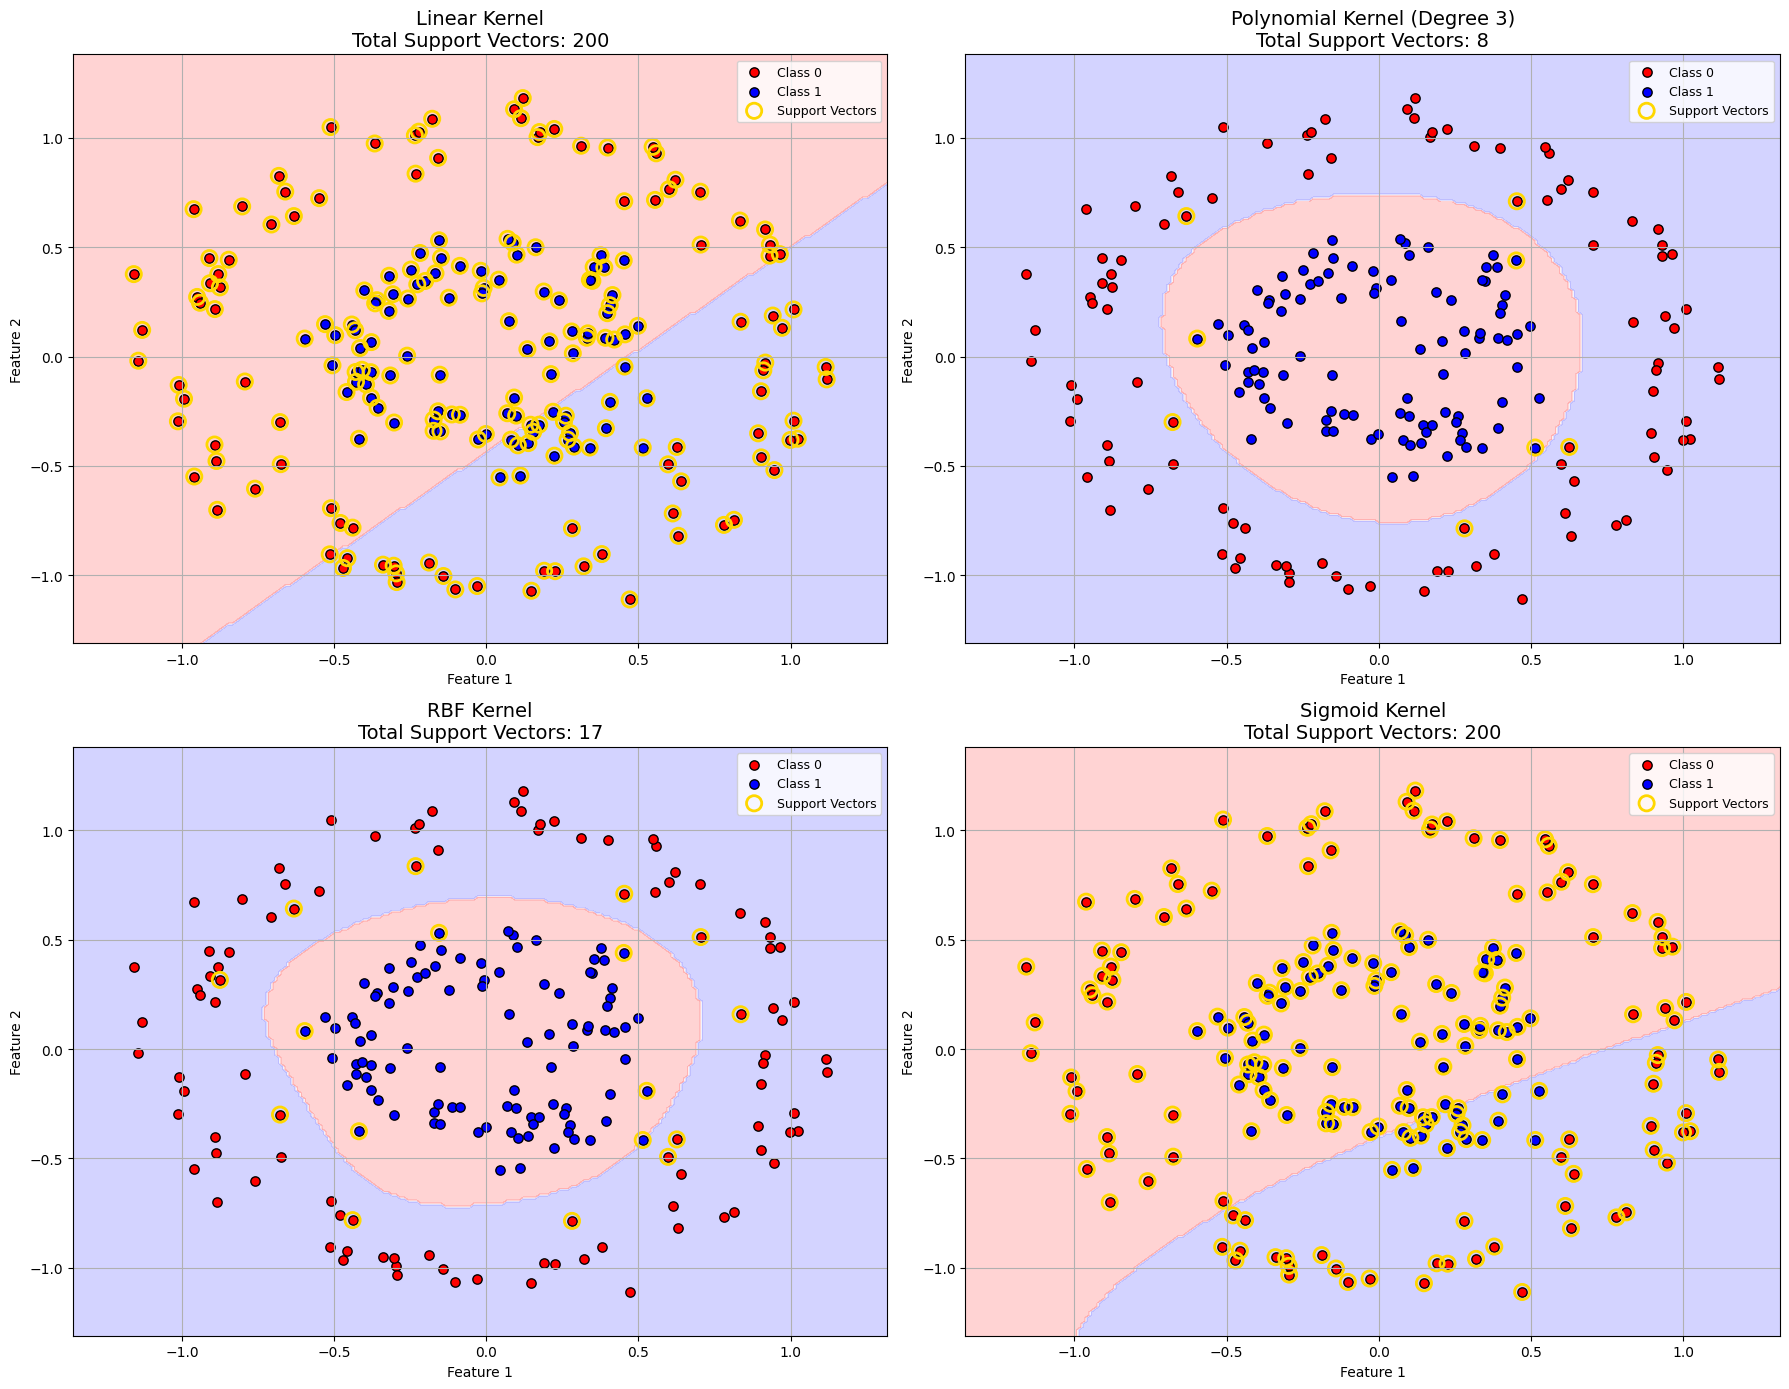

In [48]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. Define the different kernel configurations
kernels = {
    "Linear Kernel": SVC(kernel="linear", C=10, random_state=42),
    "Polynomial Kernel (Degree 3)": SVC(kernel="poly", degree=3, coef0=1, C=10, random_state=42),
    "RBF Kernel": SVC(kernel="rbf", gamma=1, C=10, random_state=42),
    "Sigmoid Kernel": SVC(kernel="sigmoid", gamma=0.1, coef0=0, C=10, random_state=42)
}

# 2. Setup the plot grid
plt.figure(figsize=(18, 14))
x_min, x_max = X_circles[:, 0].min() - 0.2, X_circles[:, 0].max() + 0.2
y_min, y_max = X_circles[:, 1].min() - 0.2, X_circles[:, 1].max() + 0.2
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

# 3. Train each model and plot its decision boundary
for idx, (name, svm_model) in enumerate(kernels.items(), 1):
    clf = Pipeline([
        ("scaler", StandardScaler()),
        ("svm_clf", svm_model)
    ])
    clf.fit(X_circles, y_circles)

    # Predict over grid
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Plotting
    ax = plt.subplot(2, 2, idx)
    ax.contourf(xx, yy, Z, alpha=0.2, cmap='bwr')

    # Scatter original points
    ax.scatter(X_circles[y_circles == 0, 0], X_circles[y_circles == 0, 1], color='red', edgecolors='k', s=45, label='Class 0')
    ax.scatter(X_circles[y_circles == 1, 0], X_circles[y_circles == 1, 1], color='blue', edgecolors='k', s=45, label='Class 1')

    # Highlight support vectors (transformed back to original space)
    sv_scaled = clf.named_steps['svm_clf'].support_vectors_
    sv_original = clf.named_steps['scaler'].inverse_transform(sv_scaled)
    ax.scatter(sv_original[:, 0], sv_original[:, 1], s=120, facecolors='none', edgecolors='gold', linewidths=2, label='Support Vectors')

    ax.set_title(f"{name}\nTotal Support Vectors: {len(sv_original)}", fontsize=14)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.grid(True)
    ax.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

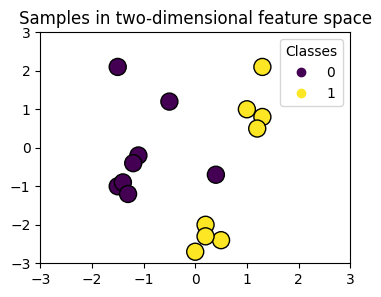

In [49]:
import matplotlib.pyplot as plt
import numpy as np

X = np.array(
    [
        [0.4, -0.7],
        [-1.5, -1.0],
        [-1.4, -0.9],
        [-1.3, -1.2],
        [-1.1, -0.2],
        [-1.2, -0.4],
        [-0.5, 1.2],
        [-1.5, 2.1],
        [1.0, 1.0],
        [1.3, 0.8],
        [1.2, 0.5],
        [0.2, -2.0],
        [0.5, -2.4],
        [0.2, -2.3],
        [0.0, -2.7],
        [1.3, 2.1],
    ]
)

y = np.array([0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1])

# Plotting settings
fig, ax = plt.subplots(figsize=(4, 3))
x_min, x_max, y_min, y_max = -3, 3, -3, 3
ax.set(xlim=(x_min, x_max), ylim=(y_min, y_max))

# Plot samples by color and add legend
scatter = ax.scatter(X[:, 0], X[:, 1], s=150, c=y, label=y, edgecolors="k")
ax.legend(*scatter.legend_elements(), loc="upper right", title="Classes")
ax.set_title("Samples in two-dimensional feature space")
plt.show()

In [51]:
from sklearn import svm
from sklearn.inspection import DecisionBoundaryDisplay


def plot_training_data_with_decision_boundary(
    kernel, ax=None, long_title=True, support_vectors=True
):
    # Train the SVC
    clf = svm.SVC(kernel=kernel, gamma=2).fit(X, y)

    # Settings for plotting
    if ax is None:
        _, ax = plt.subplots(figsize=(4, 3))
    x_min, x_max, y_min, y_max = -3, 3, -3, 3
    ax.set(xlim=(x_min, x_max), ylim=(y_min, y_max))

    # Plot decision boundary and margins
    common_params = {"estimator": clf, "X": X, "ax": ax}
    DecisionBoundaryDisplay.from_estimator(
        **common_params,
        response_method="predict",
        plot_method="pcolormesh",
        alpha=0.3,
    )
    DecisionBoundaryDisplay.from_estimator(
        **common_params,
        response_method="decision_function",
        plot_method="contour",
        levels=[-1, 0, 1],
        colors=["k", "k", "k"],
        linestyles=["--", "-", "--"],
    )

    if support_vectors:
        # Plot bigger circles around samples that serve as support vectors
        ax.scatter(
            clf.support_vectors_[:, 0],
            clf.support_vectors_[:, 1],
            s=150,
            facecolors="none",
            edgecolors="k",
        )

    # Plot samples by color and add legend
    ax.scatter(X[:, 0], X[:, 1], c=y, s=30, edgecolors="k")
    ax.legend(*scatter.legend_elements(), loc="upper right", title="Classes")
    if long_title:
        ax.set_title(f" Decision boundaries of {kernel} kernel in SVC")
    else:
        ax.set_title(kernel)

    if ax is None:
        plt.show()

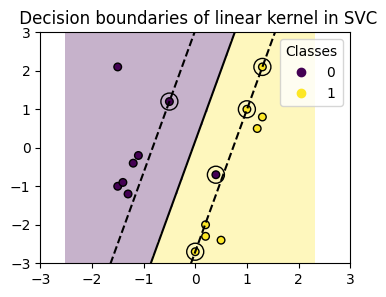

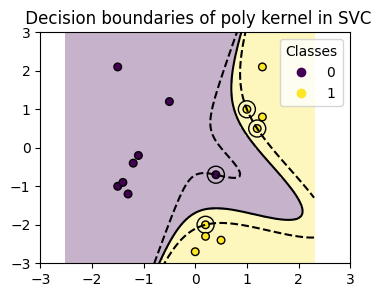

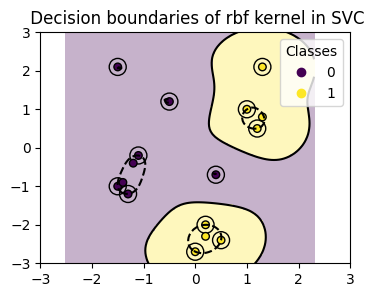

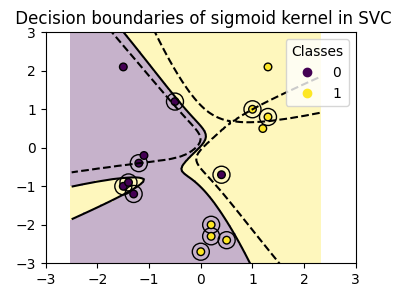

In [52]:
plot_training_data_with_decision_boundary("linear")
plot_training_data_with_decision_boundary("poly")
plot_training_data_with_decision_boundary("rbf")
plot_training_data_with_decision_boundary("sigmoid")

## Understanding the Gamma ($\gamma$) Parameter in the RBF Kernel

In the Radial Basis Function (RBF) kernel, the similarity metric between two points $\mathbf{x}$ and $\mathbf{x}'$ is computed as:

$$K(\mathbf{x}, \mathbf{x}') = \exp(-\gamma \|\mathbf{x} - \mathbf{x}'\|^2)$$

The **$\gamma$ (gamma)** parameter defines how far the influence of a single training example reaches:

* **Low Gamma (e.g., $\gamma = 0.1$):** Points far away from each other are still considered similar. The decision boundary is very smooth, generalized, and behaves more like a low-variance model.
* **High Gamma (e.g., $\gamma = 10$):** Only points extremely close to each other are considered similar. The decision boundary becomes highly curved, complex, and starts wrapping tightly around individual data points (high variance, prone to overfitting).

Let's visualize this geometric behavior on our concentric circles dataset.

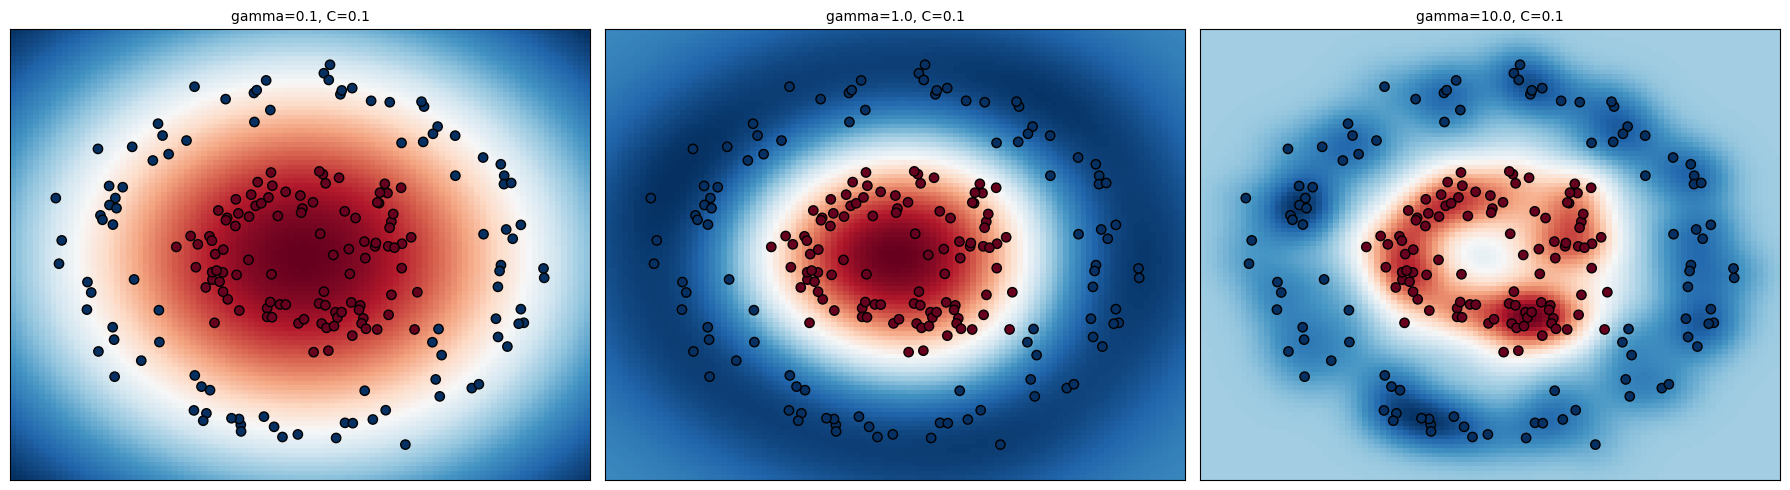

In [54]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import DecisionBoundaryDisplay

# 1. Define different gamma configurations to test
gamma_values = [0.1, 1.0, 10.0]
C_val = 0.1

plt.figure(figsize=(18, 5))

# 2. Iterate through gamma values and plot
for idx, gamma in enumerate(gamma_values, 1):
    # Build and fit pipeline
    clf = Pipeline([
        ("scaler", StandardScaler()),
        ("svm_clf", SVC(kernel="rbf", gamma=gamma, C=C_val, random_state=42))
    ])
    clf.fit(X_circles, y_circles)

    plt.subplot(1, 3, idx)
    plt.title(f"gamma={gamma}, C={C_val}", size="medium")

    # Visualize decision boundary as a continuous decision function heat map
    DecisionBoundaryDisplay.from_estimator(
        clf,
        X_circles,
        eps=0.2,
        cmap="RdBu_r",
        ax=plt.gca(),
        response_method="decision_function",
        plot_method="pcolormesh",
        shading="auto"
    )

    # Plot the original data points on top
    plt.scatter(
        X_circles[:, 0],
        X_circles[:, 1],
        c=y_circles,
        cmap=plt.cm.RdBu_r,
        edgecolors="k",
        s=45
    )

    plt.xticks(())
    plt.yticks(())

plt.tight_layout()
plt.show()

This continuous color-mesh visualization highlights the RBF decision values beautifully:

* **Smooth Gradient ($\gamma=0.1$):** The decision space is divided into broad, soft regions, showing a low-variance/high-bias boundary that ignores minor dataset fluctuations.
* **Clear Boundary ($\gamma=1.0$):** The transition from red to blue is localized and forms a clean circular pattern that fits our concentric classes perfectly.
* **High Contrast & Tight Wrapping ($\gamma=10.0$):** The decision boundary isolates local clusters, resulting in high-variance contours that tightly wrap individual observations—vividly illustrating how a high gamma can lead to overfitting.

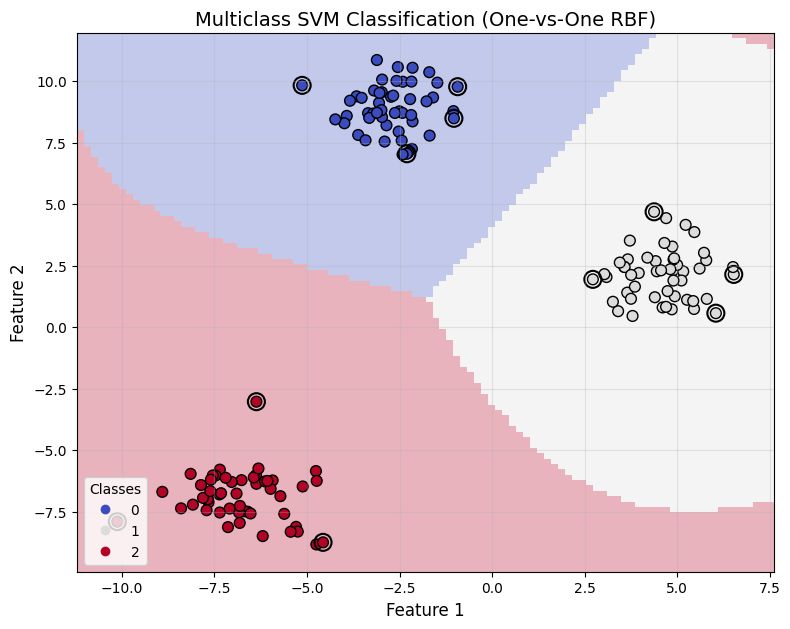

In [55]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import DecisionBoundaryDisplay

# 1. Generate a synthetic 3-class dataset
X_multi, y_multi = make_blobs(
    n_samples=150,
    centers=3,
    cluster_std=1.0,
    random_state=42
)

# 2. Build and train a multiclass SVM pipeline (using RBF Kernel)
# SVC automatically uses a One-vs-One (OvO) strategy for multiclass classification
multiclass_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm_clf", SVC(kernel="rbf", gamma=1.0, C=1.0, random_state=42))
])
multiclass_svm.fit(X_multi, y_multi)

# 3. Plot the multiclass decision boundaries
plt.figure(figsize=(9, 7))

# Plot decision boundaries with pcolormesh
DecisionBoundaryDisplay.from_estimator(
    multiclass_svm,
    X_multi,
    response_method="predict",
    plot_method="pcolormesh",
    cmap="coolwarm",
    alpha=0.3,
    ax=plt.gca()
)

# Plot the three separate classes of points
scatter = plt.scatter(
    X_multi[:, 0],
    X_multi[:, 1],
    c=y_multi,
    cmap="coolwarm",
    edgecolors="k",
    s=60
)

# Highlight support vectors
scaler = multiclass_svm.named_steps['scaler']
svm_clf = multiclass_svm.named_steps['svm_clf']
sv_original = scaler.inverse_transform(svm_clf.support_vectors_)
plt.scatter(
    sv_original[:, 0],
    sv_original[:, 1],
    s=150,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="Support Vectors"
)

plt.title("Multiclass SVM Classification (One-vs-One RBF)", fontsize=14)
plt.xlabel("Feature 1", fontsize=12)
plt.ylabel("Feature 2", fontsize=12)
plt.legend(*scatter.legend_elements(), loc="lower left", title="Classes")
plt.grid(True, alpha=0.3)
plt.show()

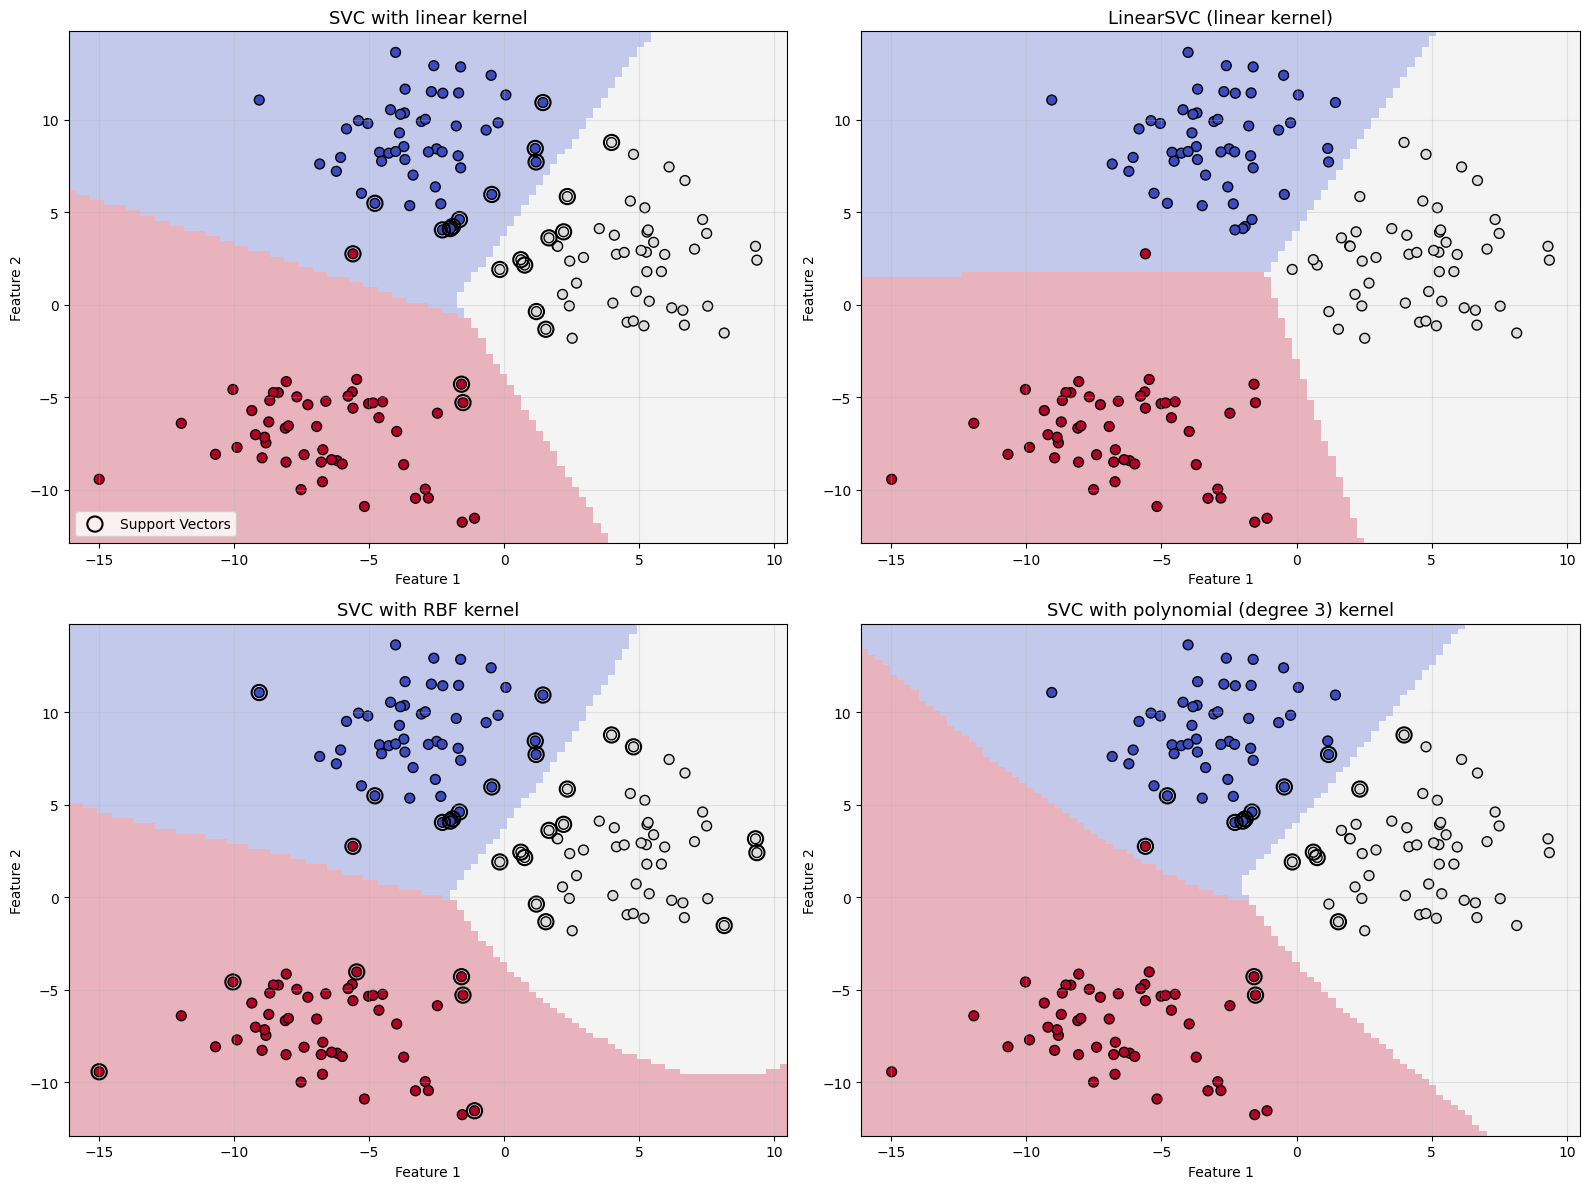

In [56]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC, LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import DecisionBoundaryDisplay

# 1. Re-generate a synthetic 3-class dataset with higher standard deviation (less separated)
X_multi, y_multi = make_blobs(
    n_samples=150,
    centers=3,
    cluster_std=2.5,
    random_state=42
)

# 2. Define the four different multiclass configurations
multiclass_models = {
    "SVC with linear kernel": SVC(kernel="linear", C=1.0, random_state=42),
    "LinearSVC (linear kernel)": LinearSVC(C=1.0, dual=False, random_state=42),
    "SVC with RBF kernel": SVC(kernel="rbf", gamma=0.5, C=1.0, random_state=42),
    "SVC with polynomial (degree 3) kernel": SVC(kernel="poly", degree=3, coef0=1.0, C=1.0, random_state=42)
}

# 3. Setup a 2x2 subplot canvas
plt.figure(figsize=(16, 12))

# 4. Fit and plot each model
for idx, (name, model) in enumerate(multiclass_models.items(), 1):
    clf = Pipeline([
        ("scaler", StandardScaler()),
        ("svm_clf", model)
    ])
    clf.fit(X_multi, y_multi)

    ax = plt.subplot(2, 2, idx)
    plt.title(name, fontsize=13)

    # Plot multiclass decision boundary partitioning
    DecisionBoundaryDisplay.from_estimator(
        clf,
        X_multi,
        response_method="predict",
        plot_method="pcolormesh",
        cmap="coolwarm",
        alpha=0.3,
        ax=ax
    )

    # Scatter original dataset points
    scatter = ax.scatter(
        X_multi[:, 0],
        X_multi[:, 1],
        c=y_multi,
        cmap="coolwarm",
        edgecolors="k",
        s=50
    )

    # Highlight support vectors (Note: LinearSVC does not support .support_vectors_ attribute)
    if hasattr(model, "support_vectors_"):
        scaler_step = clf.named_steps['scaler']
        sv_original = scaler_step.inverse_transform(model.support_vectors_)
        ax.scatter(
            sv_original[:, 0],
            sv_original[:, 1],
            s=120,
            facecolors="none",
            edgecolors="black",
            linewidths=1.5,
            label="Support Vectors"
        )

    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.grid(True, alpha=0.3)
    if idx == 1:
        ax.legend(loc="lower left")

plt.tight_layout()
plt.show()

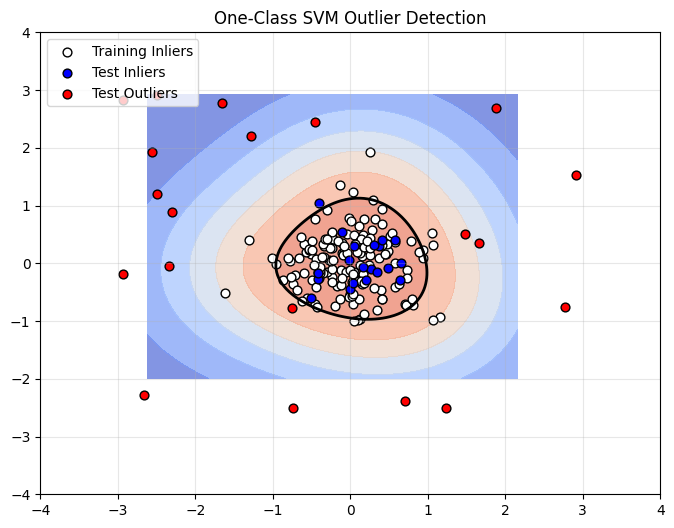

In [58]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import OneClassSVM
from sklearn.inspection import DecisionBoundaryDisplay

# 1. Generate normal training data (inliers)
np.random.seed(42)
X_train = 0.5 * np.random.randn(150, 2)

# Generate normal test data and some abnormal test data (outliers)
X_test_normal = 0.5 * np.random.randn(20, 2)
X_test_outliers = np.random.uniform(low=-3, high=3, size=(20, 2))

# 2. Fit One-Class SVM with non-linear RBF kernel
# nu specifies the expected ratio of outliers in our training set
clf = OneClassSVM(nu=0.1, kernel="rbf", gamma=0.5)
clf.fit(X_train)

# 3. Set up the plotting environment
fig, ax = plt.subplots(figsize=(8, 6))

# Display the decision boundaries and density contours
DecisionBoundaryDisplay.from_estimator(
    clf,
    X_train,
    response_method="decision_function",
    plot_method="contourf",
    cmap="coolwarm",
    alpha=0.7,
    ax=ax
)

# Draw the exact boundary where decision function is 0
DecisionBoundaryDisplay.from_estimator(
    clf,
    X_train,
    response_method="decision_function",
    plot_method="contour",
    levels=[0],
    colors="black",
    linewidths=2,
    ax=ax
)

# Plot datasets
ax.scatter(X_train[:, 0], X_train[:, 1], c="white", edgecolors="k", s=40, label="Training Inliers")
ax.scatter(X_test_normal[:, 0], X_test_normal[:, 1], c="blue", edgecolors="k", s=40, label="Test Inliers")
ax.scatter(X_test_outliers[:, 0], X_test_outliers[:, 1], c="red", edgecolors="k", s=40, label="Test Outliers")

ax.set_title("One-Class SVM Outlier Detection")
ax.set_xlim(-4, 4)
ax.set_ylim(-4, 4)
ax.legend(loc="upper left")
ax.grid(True, alpha=0.3)
plt.show()

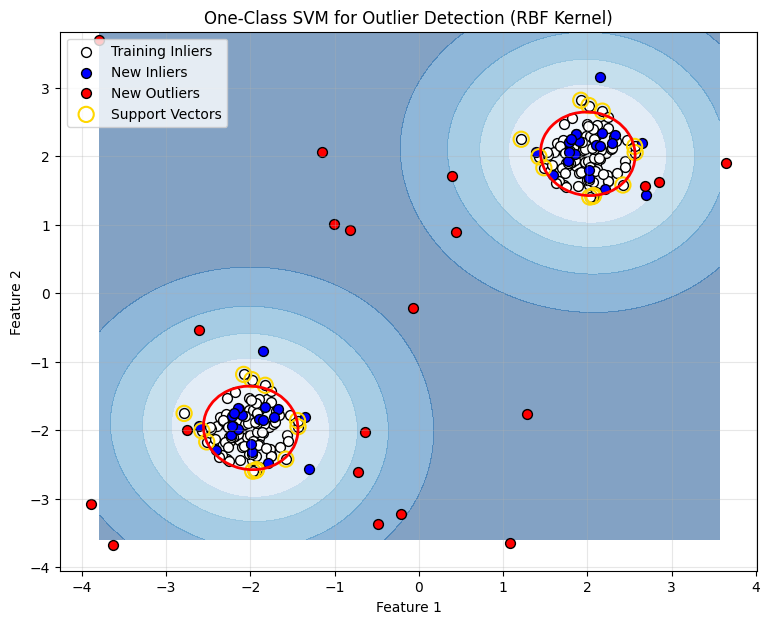

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import OneClassSVM
from sklearn.inspection import DecisionBoundaryDisplay

# 1. Generate synthetic training data (mostly inliers)
np.random.seed(42)
X_train = 0.3 * np.random.randn(100, 2)
X_train = np.r_[X_train + 2, X_train - 2]  # Two clusters of inliers

# Generate some new normal observations (test inliers)
X_test = 0.3 * np.random.randn(20, 2)
X_test = np.r_[X_test + 2, X_test - 2]

# Generate some abnormal observations (test outliers)
X_outliers = np.random.uniform(low=-4, high=4, size=(20, 2))

# 2. Fit the One-Class SVM model with RBF kernel
# nu is an upper bound on the fraction of training errors and a lower bound of the fraction of support vectors
clf = OneClassSVM(nu=0.1, kernel="rbf", gamma=0.5)
clf.fit(X_train)

# Predict labels (-1 for outliers, 1 for inliers)
y_pred_train = clf.predict(X_train)
y_pred_test = clf.predict(X_test)
y_pred_outliers = clf.predict(X_outliers)

# 3. Plotting the results and decision boundary
fig, ax = plt.subplots(figsize=(9, 7))

# Plot the decision boundary and margin zone
DecisionBoundaryDisplay.from_estimator(
    clf,
    X_train,
    response_method="decision_function",
    plot_method="contourf",
    cmap="Blues_r",
    alpha=0.5,
    ax=ax
)

# Plot the decision boundary line (threshold where decision_function = 0)
DecisionBoundaryDisplay.from_estimator(
    clf,
    X_train,
    response_method="decision_function",
    plot_method="contour",
    levels=[0],
    colors="red",
    linewidths=2,
    ax=ax
)

# Plot the data points
p1 = ax.scatter(X_train[:, 0], X_train[:, 1], c="white", s=50, edgecolors="k", label="Training Inliers")
p2 = ax.scatter(X_test[:, 0], X_test[:, 1], c="blue", s=50, edgecolors="k", label="New Inliers")
p3 = ax.scatter(X_outliers[:, 0], X_outliers[:, 1], c="red", s=50, edgecolors="k", label="New Outliers")

# Highlight Support Vectors
sv = clf.support_vectors_
ax.scatter(sv[:, 0], sv[:, 1], s=120, facecolors="none", edgecolors="gold", linewidths=1.5, label="Support Vectors")

ax.set_title("One-Class SVM for Outlier Detection (RBF Kernel)")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend(loc="upper left")
ax.grid(True, alpha=0.3)
plt.show()

## Support Vector Regression (SVR) - Linear Formulation

In Support Vector Regression (SVR), the goal is to find a function $f(x) = \langle w, x \rangle + b$ that has at most $\epsilon$ deviation from the actually obtained targets $y_i$ for all the training data, and at the same time is as flat as possible.

### Optimization Problem
We want to minimize the norm of the weight vector $w$ while keeping the prediction errors within an $\epsilon$-tube:

$$\min_{w, b} \frac{1}{2} \|w\|^2$$
$$\text{subject to } \begin{cases} y_i - \langle w, x_i \rangle - b \le \epsilon \\ \langle w, x_i \rangle + b - y_i \le \epsilon \end{cases}$$

### Soft Margin Formulation
To allow for errors (points outside the $\epsilon$-tube), we introduce slack variables $\xi_i, \xi_i^* \ge 0$:

$$\min_{w, b, \xi, \xi^*} \frac{1}{2} \|w\|^2 + C \sum_{i=1}^{n} (\xi_i + \xi_i^*)$$
$$\text{subject to } \begin{cases} y_i - \langle w, x_i \rangle - b \le \epsilon + \xi_i \\ \langle w, x_i \rangle + b - y_i \le \epsilon + \xi_i^* \\ \xi_i, \xi_i^* \ge 0 \end{cases}$$

Where:
- $C > 0$ determines the trade-off between the flatness of $f$ and the amount up to which deviations larger than $\epsilon$ are tolerated.
- $\epsilon$ controls the width of the tube within which no penalty is associated with training errors.


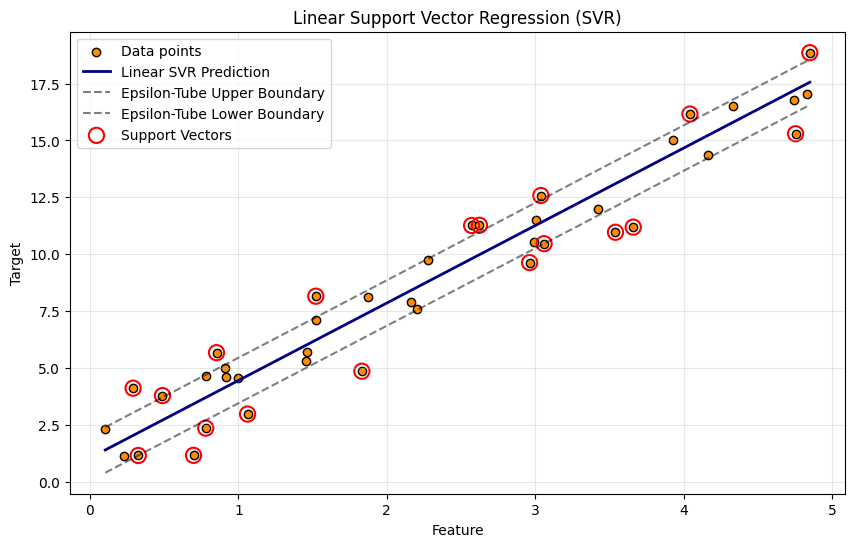

In [60]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVR

# 1. Generate synthetic regression data with some noise
np.random.seed(42)
X = np.sort(5 * np.random.rand(40, 1), axis=0)
y = 3 * X.ravel() + 2 + np.random.normal(0, 1.5, X.shape[0])

# 2. Fit Support Vector Regression with a linear kernel
epsilon = 1.0
svr_lin = SVR(kernel='linear', C=10.0, epsilon=epsilon)
svr_lin.fit(X, y)

# Predict using the fitted model
y_pred = svr_lin.predict(X)

# 3. Visualization
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='darkorange', label='Data points', edgecolors='k')
plt.plot(X, y_pred, color='navy', lw=2, label='Linear SVR Prediction')

# Plot epsilon-tube boundaries
plt.plot(X, y_pred + epsilon, 'k--', alpha=0.5, label='Epsilon-Tube Upper Boundary')
plt.plot(X, y_pred - epsilon, 'k--', alpha=0.5, label='Epsilon-Tube Lower Boundary')

# Highlight support vectors (points on or outside the tube)
sv_indices = svr_lin.support_
plt.scatter(X[sv_indices], y[sv_indices], s=120, facecolors='none', edgecolors='red', linewidths=1.5, label='Support Vectors')

plt.xlabel('Feature')
plt.ylabel('Target')
plt.title('Linear Support Vector Regression (SVR)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Visualizing SVR on a Larger, Non-Linear Dataset

When dealing with non-linear relationships, a linear SVR kernel is insufficient. We can leverage the **Kernel Trick** (e.g., using Polynomial or Radial Basis Function (RBF) kernels) to map our features into a higher-dimensional space where a linear fit is possible.

Let's generate a larger non-linear dataset based on a sine wave with added noise, and compare three SVR models:
1. **Linear SVR**
2. **Polynomial SVR (Degree 3)**
3. **RBF SVR**


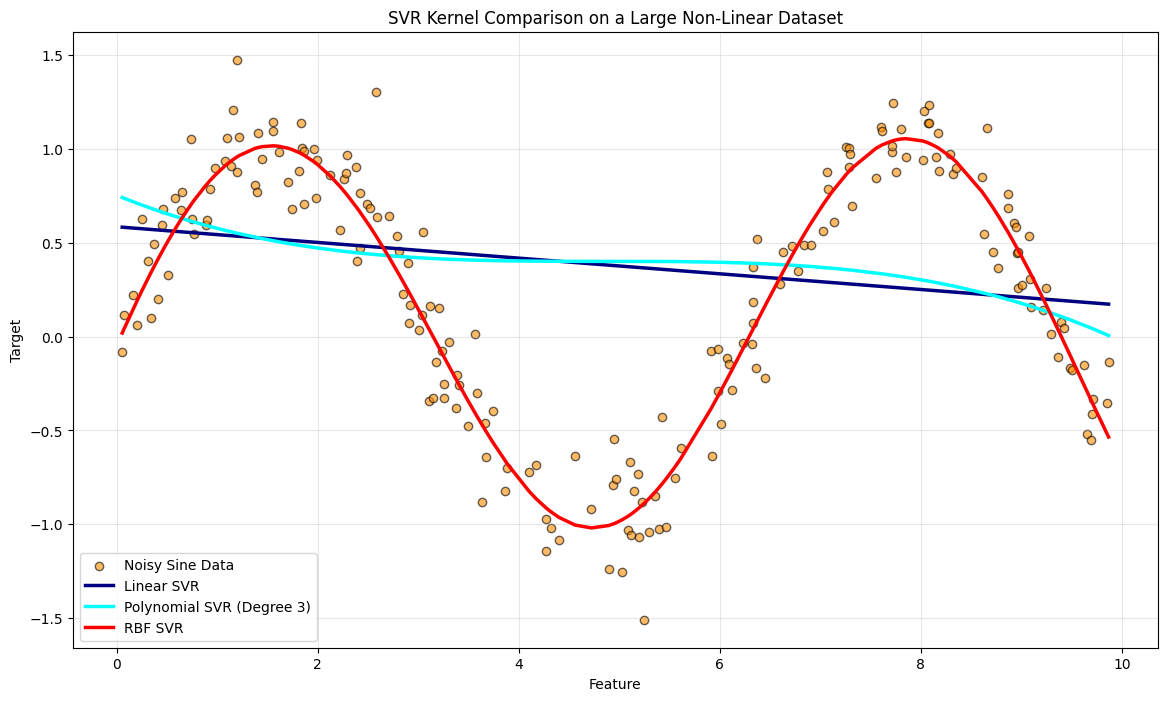

In [61]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 1. Generate a larger, non-linear synthetic dataset
np.random.seed(42)
X_large = np.sort(10 * np.random.rand(200, 1), axis=0)
y_large = np.sin(X_large).ravel() + np.random.normal(0, 0.2, X_large.shape[0])

# 2. Define SVR models
# Feature scaling is highly recommended for SVR, especially with RBF/Poly kernels
svr_linear = make_pipeline(StandardScaler(), SVR(kernel='linear', C=100.0, epsilon=0.1))
svr_poly = make_pipeline(StandardScaler(), SVR(kernel='poly', degree=3, C=100.0, epsilon=0.1))
svr_rbf = make_pipeline(StandardScaler(), SVR(kernel='rbf', C=100.0, gamma=0.5, epsilon=0.1))

# Fit the models
svr_linear.fit(X_large, y_large)
svr_poly.fit(X_large, y_large)
svr_rbf.fit(X_large, y_large)

# Predict
y_pred_linear = svr_linear.predict(X_large)
y_pred_poly = svr_poly.predict(X_large)
y_pred_rbf = svr_rbf.predict(X_large)

# 3. Visualize the comparison
plt.figure(figsize=(14, 8))
plt.scatter(X_large, y_large, color='darkorange', alpha=0.6, edgecolors='k', label='Noisy Sine Data')

plt.plot(X_large, y_pred_linear, color='navy', lw=2.5, label='Linear SVR')
plt.plot(X_large, y_pred_poly, color='cyan', lw=2.5, label='Polynomial SVR (Degree 3)')
plt.plot(X_large, y_pred_rbf, color='red', lw=2.5, label='RBF SVR')

# Highlight RBF Support Vectors as reference
sv_indices = svr_rbf.named_steps['svr'].support_
#plt.scatter(X_large[sv_indices], y_large[sv_indices], s=100, facecolors='none', edgecolors='black', linewidths=1, label='RBF Support Vectors')

plt.xlabel('Feature')
plt.ylabel('Target')
plt.title('SVR Kernel Comparison on a Large Non-Linear Dataset')
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)
plt.show()